# 12 · Autograd: a tiny automatic-differentiation engine

In notebooks 02–11 we derived every backward pass **by hand**. That's the best way to learn, and the worst way to build: each new layer meant new calculus and a new chance for a bug. **Automatic differentiation** removes that work. This notebook builds the engine that PyTorch and JAX are based on, in about 150 lines of numpy.

## The idea: record, then replay backwards
Every operation does two things: compute its output, and **remember how to push gradients back** to its inputs. A model's forward pass therefore builds a *graph*. Calling `.backward()` walks the graph from the loss back to the parameters (**reverse-mode** autodiff), applying the chain rule at each node.

For a node $z=f(x,y)$ whose upstream gradient is $\bar z=\partial L/\partial z$, each input receives
$$\bar x \mathrel{+}= \bar z\cdot\frac{\partial f}{\partial x},\qquad \bar y \mathrel{+}= \bar z\cdot\frac{\partial f}{\partial y}$$

Three details make it correct:
1. **Accumulate (`+=`), don't assign.** If a value is used twice (like $x\cdot x$), its gradient is the *sum* of both paths.
2. **Process nodes in reverse topological order,** so a node's gradient is complete before it's pushed to its parents.
3. **Broadcasting.** If `b` of shape `(4,)` was broadcast against `(3,4)`, its gradient must be *summed back* to shape `(4,)`.

| op | local rule (given upstream $\bar z$) |
|---|---|
| $z=x+y$ | $\bar x \mathrel{+}= \bar z,\ \ \bar y \mathrel{+}= \bar z$ |
| $z=x\cdot y$ | $\bar x \mathrel{+}= \bar z\,y,\ \ \bar y \mathrel{+}= \bar z\,x$ |
| $Z=XW$ | $\bar X \mathrel{+}= \bar Z W^{\top},\ \ \bar W \mathrel{+}= X^{\top}\bar Z$ |
| $z=\tanh x$ | $\bar x \mathrel{+}= \bar z\,(1-z^2)$ |
| $z=\log x$ | $\bar x \mathrel{+}= \bar z / x$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## The engine
`Tensor` wraps a numpy array. Each operation creates a new `Tensor` that stores its **parents** and a `_backward` closure containing that operation's local rule. `unbroadcast` implements detail 3.

**A gotcha worth knowing:** an expression like `y * tensor` (numpy array on the left) would make numpy try to multiply element-by-element *over the Tensor object* and silently produce garbage. `__array_ufunc__ = None` tells numpy to defer to our `__rmul__` instead. (The first version of this notebook had that bug: every op passed its finite-difference test, but the comparison with notebook 02 below failed, which is exactly why that second test exists.)

In [2]:
def unbroadcast(grad, shape):
    """Sum a broadcasted gradient back down to `shape`."""
    while grad.ndim > len(shape):
        grad = grad.sum(axis=0)
    for i, s in enumerate(shape):
        if s == 1 and grad.shape[i] != 1:
            grad = grad.sum(axis=i, keepdims=True)
    return grad


def as_tensor(x):
    return x if isinstance(x, Tensor) else Tensor(x)


class Tensor:
    # Without this, `ndarray * Tensor` makes numpy broadcast over the Tensor as an opaque object and silently
    # return garbage. Setting it to None makes numpy defer, so Python calls our reflected operator (__rmul__ etc.).
    __array_ufunc__ = None

    def __init__(self, data, parents=(), op=""):
        self.data = np.array(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self.parents, self.op = tuple(parents), op
        self._backward = lambda: None

    @property
    def shape(self):
        return self.data.shape

    def __repr__(self):
        return f"Tensor(shape={self.shape}, op='{self.op}')"

    # ---- the engine itself ----
    def backward(self):
        order, seen, stack = [], set(), [(self, False)]
        while stack:                                    # iterative DFS -> reverse topological order, no recursion limit
            node, expanded = stack.pop()
            if expanded:
                order.append(node)
            elif node not in seen:
                seen.add(node)
                stack.append((node, True))
                stack.extend((p, False) for p in node.parents)
        self.grad = np.ones_like(self.data)             # dL/dL = 1
        for node in reversed(order):
            node._backward()

    # ---- arithmetic ----
    def __add__(self, other):
        other = as_tensor(other)
        out = Tensor(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += unbroadcast(out.grad, self.shape)
            other.grad += unbroadcast(out.grad, other.shape)
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = as_tensor(other)
        out = Tensor(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += unbroadcast(out.grad * other.data, self.shape)
            other.grad += unbroadcast(out.grad * self.data, other.shape)
        out._backward = _backward
        return out

    def __pow__(self, p):                                # scalar exponent
        out = Tensor(self.data ** p, (self,), f"**{p}")
        def _backward():
            self.grad += out.grad * p * self.data ** (p - 1)
        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1.0

    def __sub__(self, other):
        return self + (-as_tensor(other))

    def __truediv__(self, other):
        return self * as_tensor(other) ** -1

    __radd__ = __add__
    __rmul__ = __mul__

    def __rsub__(self, other):
        return as_tensor(other) + (-self)

    def __rtruediv__(self, other):
        return as_tensor(other) * self ** -1

    # ---- linear algebra and shape ----
    def __matmul__(self, other):                         # (..., n, k) @ (..., k, m); both at least 2-D
        other = as_tensor(other)
        out = Tensor(self.data @ other.data, (self, other), "@")
        def _backward():
            self.grad += unbroadcast(out.grad @ np.swapaxes(other.data, -1, -2), self.shape)
            other.grad += unbroadcast(np.swapaxes(self.data, -1, -2) @ out.grad, other.shape)
        out._backward = _backward
        return out

    def transpose(self, *axes):
        axes = axes or tuple(reversed(range(self.data.ndim)))
        out = Tensor(self.data.transpose(axes), (self,), "T")
        def _backward():
            self.grad += out.grad.transpose(np.argsort(axes))
        out._backward = _backward
        return out

    @property
    def T(self):
        return self.transpose()

    def reshape(self, *shape):
        out = Tensor(self.data.reshape(shape), (self,), "reshape")
        def _backward():
            self.grad += out.grad.reshape(self.shape)
        out._backward = _backward
        return out

    # ---- reductions ----
    def sum(self, axis=None, keepdims=False):
        out = Tensor(self.data.sum(axis=axis, keepdims=keepdims), (self,), "sum")
        def _backward():
            g = out.grad
            if axis is not None and not keepdims:
                g = np.expand_dims(g, axis)
            self.grad += np.broadcast_to(g, self.shape)
        out._backward = _backward
        return out

    def mean(self, axis=None, keepdims=False):
        s = self.sum(axis, keepdims)
        return s * (s.data.size / self.data.size)

    # ---- elementwise nonlinearities ----
    def _unary(self, data, local_grad, op):
        out = Tensor(data, (self,), op)
        def _backward():
            self.grad += out.grad * local_grad(out.data)
        out._backward = _backward
        return out

    def exp(self):
        return self._unary(np.exp(self.data), lambda z: z, "exp")

    def log(self):
        out = Tensor(np.log(self.data), (self,), "log")
        def _backward():
            self.grad += out.grad / self.data
        out._backward = _backward
        return out

    def tanh(self):
        return self._unary(np.tanh(self.data), lambda z: 1 - z ** 2, "tanh")

    def sigmoid(self):
        return self._unary(1 / (1 + np.exp(-self.data)), lambda z: z * (1 - z), "sigmoid")

    def relu(self):
        out = Tensor(np.maximum(self.data, 0), (self,), "relu")
        def _backward():
            self.grad += out.grad * (self.data > 0)
        out._backward = _backward
        return out

    def softplus(self):                                  # log(1 + e^x), stable; derivative is sigmoid(x)
        out = Tensor(np.logaddexp(0, self.data), (self,), "softplus")
        def _backward():
            self.grad += out.grad / (1 + np.exp(-self.data))
        out._backward = _backward
        return out


def softmax(x, axis=-1):
    # Subtracting the max is a numerical-stability trick; softmax is shift-invariant, so treating it as a constant is exact.
    e = (x - x.data.max(axis=axis, keepdims=True)).exp()
    return e / e.sum(axis=axis, keepdims=True)

## It works: a first look
A tiny expression, its gradient from the engine, and the graph it recorded. Note `x` is used twice, so its gradient is the sum of two paths: $\partial/\partial x\,[x^2+x\,w]=2x+w$.

In [3]:
x, w = Tensor(3.0), Tensor(-2.0)
y = x * x + x * w                      # x is used twice
y.backward()
print(f"y = {y.data}")
print(f"dy/dx = {x.grad}   (expected 2x + w = {2 * 3.0 + -2.0})")
print(f"dy/dw = {w.grad}   (expected x = 3.0)")
assert x.grad == 4.0 and w.grad == 3.0
assert isinstance(np.ones(2) * Tensor([1.0, 2.0]), Tensor), "ndarray on the left must defer to Tensor (see __array_ufunc__)"


def trace(root):
    """List the recorded graph in forward order."""
    order, seen = [], set()
    def visit(n):
        if n not in seen:
            seen.add(n); [visit(p) for p in n.parents]; order.append(n)
    visit(root)
    return order


print("\nrecorded graph (forward order):")
for node in trace(y):
    print(f"  {node.op or 'leaf':<6} shape={node.shape}  parents={[p.op or 'leaf' for p in node.parents]}")

y = 3.0
dy/dx = 4.0   (expected 2x + w = 4.0)
dy/dw = 3.0   (expected x = 3.0)

recorded graph (forward order):
  leaf   shape=()  parents=[]
  *      shape=()  parents=['leaf', 'leaf']
  leaf   shape=()  parents=[]
  *      shape=()  parents=['leaf', 'leaf']
  +      shape=()  parents=['*', '*']


## Test 1 · every op against finite differences
For each operation, build a random scalar loss $L=\sum R\odot f(\text{inputs})$ (a random weighting `R` so the gradient isn't trivially symmetric) and compare the engine's gradient with a central finite difference for **every input entry**.

In [4]:
def numeric_check(fn, shapes, positive=(), seed=0, eps=1e-6):
    """Max |analytic - numeric| over all entries of all inputs of fn(*tensors) -> Tensor."""
    rng = np.random.RandomState(seed)
    arrays = [rng.randn(*s) for s in shapes]
    for i in positive:
        arrays[i] = np.abs(arrays[i]) + 0.5                       # keep log() inputs positive
    R = rng.randn(*fn(*[Tensor(a) for a in arrays]).shape)

    def loss(arrs):
        return (fn(*[Tensor(a) for a in arrs]) * R).sum()

    tensors = [Tensor(a) for a in arrays]
    (fn(*tensors) * R).sum().backward()
    worst = 0.0
    for k, t in enumerate(tensors):
        for idx in np.ndindex(*arrays[k].shape):
            plus = [a.copy() for a in arrays]; plus[k][idx] += eps
            minus = [a.copy() for a in arrays]; minus[k][idx] -= eps
            num = (loss(plus).data - loss(minus).data) / (2 * eps)
            worst = max(worst, abs(num - t.grad[idx]) / (abs(num) + abs(t.grad[idx]) + 1e-6))
    return worst


cases = {
    "add (broadcast)":     (lambda a, b: a + b,                         [(3, 4), (4,)], ()),
    "sub":                 (lambda a, b: a - b,                         [(3, 4), (3, 4)], ()),
    "mul (broadcast)":     (lambda a, b: a * b,                         [(3, 1), (1, 4)], ()),
    "div":                 (lambda a, b: a / b,                         [(3, 4), (3, 4)], (1,)),
    "pow":                 (lambda a: a ** 3,                           [(3, 4)], ()),
    "matmul":              (lambda a, b: a @ b,                         [(3, 4), (4, 5)], ()),
    "matmul (batched)":    (lambda a, b: a @ b,                         [(2, 3, 4), (2, 4, 5)], ()),
    "matmul (bcast batch)": (lambda a, b: a @ b,                        [(2, 3, 4), (4, 5)], ()),
    "sum(axis)":           (lambda a: a.sum(axis=1),                    [(3, 4)], ()),
    "mean(keepdims)":      (lambda a: a.mean(axis=0, keepdims=True),    [(3, 4)], ()),
    "transpose":           (lambda a: a.transpose(1, 0, 2),             [(2, 3, 4)], ()),
    "reshape":             (lambda a: a.reshape(4, 3),                  [(3, 4)], ()),
    "exp":                 (lambda a: a.exp(),                          [(3, 4)], ()),
    "log":                 (lambda a: a.log(),                          [(3, 4)], (0,)),
    "tanh":                (lambda a: a.tanh(),                         [(3, 4)], ()),
    "sigmoid":             (lambda a: a.sigmoid(),                      [(3, 4)], ()),
    "relu":                (lambda a: a.relu(),                         [(3, 4)], ()),
    "softplus":            (lambda a: a.softplus(),                     [(3, 4)], ()),
    "softmax":             (lambda a: softmax(a),                       [(3, 5)], ()),
    "reused node (x*x+x)": (lambda a: a * a + a,                        [(3, 4)], ()),
}

print(f"{'op':<24}{'worst relative error'}")
for name, (fn, shapes, pos) in cases.items():
    err = numeric_check(fn, shapes, pos)
    print(f"{name:<24}{err:.2e}")
    assert err < 1e-6, f"{name}: autograd gradient disagrees with finite differences"

op                      worst relative error
add (broadcast)         1.29e-09
sub                     2.65e-10
mul (broadcast)         6.98e-10
div                     9.42e-10
pow                     7.33e-09
matmul                  4.79e-09
matmul (batched)        7.75e-09
matmul (bcast batch)    6.66e-09
sum(axis)               9.70e-10
mean(keepdims)          3.99e-10
transpose               1.29e-09
reshape                 9.70e-10
exp                     2.51e-09
log                     2.29e-09
tanh                    6.08e-09
sigmoid                 1.79e-09
relu                    9.70e-10
softplus                2.58e-09
softmax                 2.01e-09
reused node (x*x+x)     2.65e-09


## Test 2 · against our hand-derived backprop (notebook 02)
The strongest check available: the engine must reproduce, to floating-point precision, the gradients we derived on paper for the XOR network in notebook 02:
$$dZ_2=\tfrac{A_2-y}{m},\ dW_2=A_1^{\top}dZ_2,\ db_2=\textstyle\sum dZ_2,\ dA_1=dZ_2W_2^{\top},\ dZ_1=dA_1\odot A_1(1-A_1),\ dW_1=X^{\top}dZ_1,\ db_1=\textstyle\sum dZ_1$$
Here the engine gets none of those formulas. It only gets the forward pass written as ordinary tensor expressions.

In [5]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
r = np.random.RandomState(0)
W1, b1 = r.randn(2, 4) * 0.8, r.randn(1, 4) * 0.1
W2, b2 = r.randn(4, 1) * 0.8, r.randn(1, 1) * 0.1

# --- autograd: forward pass only ---
tW1, tb1, tW2, tb2 = Tensor(W1), Tensor(b1), Tensor(W2), Tensor(b2)
A2 = ((Tensor(X) @ tW1 + tb1).sigmoid() @ tW2 + tb2).sigmoid()
loss = -(y * A2.log() + (1 - y) * (1 - A2).log()).mean()
loss.backward()

# --- hand-derived backprop from notebook 02 ---
sig = lambda z: 1 / (1 + np.exp(-z))
A1m = sig(X @ W1 + b1); A2m = sig(A1m @ W2 + b2)
dZ2 = (A2m - y) / len(y)
dW2, db2 = A1m.T @ dZ2, dZ2.sum(axis=0, keepdims=True)
dZ1 = (dZ2 @ W2.T) * A1m * (1 - A1m)
dW1, db1 = X.T @ dZ1, dZ1.sum(axis=0, keepdims=True)

print(f"{'param':<6}{'max |autograd - manual|'}")
worst = 0.0
for name, t, manual in [("W1", tW1, dW1), ("b1", tb1, db1), ("W2", tW2, dW2), ("b2", tb2, db2)]:
    d = np.abs(t.grad - manual).max()
    worst = max(worst, d)
    print(f"{name:<6}{d:.2e}")
assert worst < 1e-12, "autograd should reproduce the hand-derived gradients to machine precision"

param max |autograd - manual|
W1    1.73e-18
b1    3.47e-18
W2    0.00e+00
b2    0.00e+00


## Using it: a neural-network library in 25 lines
With the engine in place, `Linear`, an MLP and Adam need **no backward code at all**. Parameters are just `Tensor`s; the optimizer reads `.grad`. We train on the two spirals from notebook 11.

In [6]:
class Linear:
    def __init__(self, d_in, d_out):
        self.W = Tensor(np.random.randn(d_in, d_out) * np.sqrt(2.0 / d_in))
        self.b = Tensor(np.zeros((1, d_out)))

    def __call__(self, x):
        return x @ self.W + self.b

    def parameters(self):
        return [self.W, self.b]


class MLP:
    def __init__(self, sizes):
        self.layers = [Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])]

    def __call__(self, x):
        for layer in self.layers[:-1]:
            x = layer(x).relu()
        return self.layers[-1](x)

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


class Adam:
    def __init__(self, params, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.params, self.lr, self.b1, self.b2, self.eps, self.t = params, lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p.data) for p in params]
        self.v = [np.zeros_like(p.data) for p in params]

    def zero_grad(self):
        for p in self.params:
            p.grad[...] = 0

    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * p.grad
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * p.grad ** 2
            p.data -= self.lr * (self.m[i] / (1 - self.b1 ** self.t)) / (np.sqrt(self.v[i] / (1 - self.b2 ** self.t)) + self.eps)

In [7]:
def make_spirals(n, seed, noise=0.1):
    r = np.random.RandomState(seed)
    t = np.sqrt(r.uniform(0.02, 1, n)) * 3.5 * np.pi
    X0 = np.c_[t * np.cos(t), t * np.sin(t)]
    Xs = np.vstack([X0, -X0]) / (3.5 * np.pi) + r.randn(2 * n, 2) * noise * 0.2
    ys = np.r_[np.zeros(n), np.ones(n)][:, None]
    p = r.permutation(2 * n)
    return Xs[p], ys[p]


X_train, y_train = make_spirals(300, seed=0)
X_test, y_test = make_spirals(300, seed=1)

np.random.seed(1)
net = MLP([2, 48, 48, 1])
opt = Adam(net.parameters(), lr=0.01)
history = []
for step in range(1500):
    logits = net(Tensor(X_train))
    loss = (logits.softplus() - y_train * logits).mean()           # binary cross-entropy with logits
    opt.zero_grad()
    loss.backward()
    opt.step()
    history.append(float(loss.data))

acc = lambda Xs, ys: float(np.mean((net(Tensor(Xs)).data > 0) == ys))
print(f"final loss {history[-1]:.4f} | train acc {acc(X_train, y_train):.1%} | test acc {acc(X_test, y_test):.1%}")
assert acc(X_test, y_test) > 0.9, "autograd-trained MLP should solve the spirals"

final loss 0.0000 | train acc 100.0% | test acc 99.8%


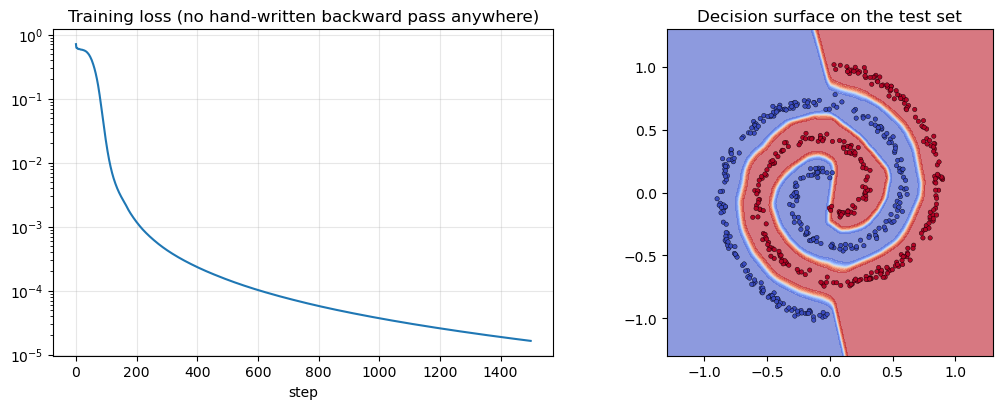

In [8]:
xx, yy = np.meshgrid(np.linspace(-1.3, 1.3, 220), np.linspace(-1.3, 1.3, 220))
Z = net(Tensor(np.c_[xx.ravel(), yy.ravel()])).sigmoid().data.reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(history); axes[0].set(title="Training loss (no hand-written backward pass anywhere)", xlabel="step", yscale="log"); axes[0].grid(alpha=0.3)
axes[1].contourf(xx, yy, Z, levels=20, cmap="coolwarm", alpha=0.6, vmin=0, vmax=1)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap="coolwarm", s=10, edgecolor="k", linewidth=0.3)
axes[1].set(title="Decision surface on the test set"); axes[1].set_aspect("equal")
plt.tight_layout(); plt.show()

## The payoff: self-attention with zero backward code
In notebook 07, attention needed a hand-derived softmax Jacobian, per-head reshaping and $d_Q,d_K,d_V$ formulas, then a finite-difference check to trust it. With the engine it is just the forward pass, written like the math, and gradients come for free. We still verify with finite differences, because trust but verify.

In [9]:
def self_attention(x, Wq, Wk, Wv):
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    A = softmax(q @ k.transpose(0, 2, 1) / np.sqrt(q.shape[-1]))      # (batch, L, L)
    return A @ v


err = numeric_check(self_attention, [(2, 5, 4), (4, 4), (4, 4), (4, 4)])
print(f"self-attention (batched, 2 sequences of length 5): worst relative error {err:.2e}")
assert err < 1e-6, "attention gradients from autograd disagree with finite differences"

self-attention (batched, 2 sequences of length 5): worst relative error 5.95e-09


## Takeaways
- **Autodiff = record the graph, replay it backwards**, applying the chain rule one *local* rule at a time. Each op only needs to know its own derivative.
- **Accumulate, order, unbroadcast** are the three details that make it correct; the finite-difference tests above exercise all of them.
- The engine reproduces our **hand-derived gradients to machine precision**, which shows all those notebooks derived the right thing.
- Once you have it, new architectures (attention, residual blocks, ...) are *just forward code*. That's the practical reason frameworks exist.
- This engine is deliberately minimal. What's missing: in-place ops, indexing/gather (needed for embeddings), convolution (it would be `im2col` as an indexing op plus a matmul), GPU kernels, and **memory management**. Real frameworks free intermediate activations or recompute them (gradient checkpointing).

That completes the roadmap: perceptron → backprop → optimizers → regularization → CNN → RNN/LSTM → transformer → autoencoder/VAE → GAN → word2vec → ResNet → autograd.